# CUAD EDA

This notebook explores CUAD for **Jargonaut**, our contract question-answering project.

- understand the dataset structure,
- check missing values, duplicates and evidence offsets,
- inspect clause categories and unanswered questions,
- examine contract lengths and multiple evidence spans,
- identify a suitable format for evidence extraction training.

Source: [Official CUAD repository](https://github.com/The-Atticus-Project/cuad).

Detailed EDA uses training contracts only. Test contracts are reserved for final evaluation.

In [1]:
# Importing necessary libraries
import json
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import matplotlib.pyplot as plt

a. loading the dataset

The first run downloads the official archive into `Data/CUAD` beside this notebook. Later runs reuse it. In Colab, change `data_dir` to a mounted Drive folder if you want to keep the download between sessions.

`CUADv1.json` preserves all answers for each question. The official training file separates answers into individual records, so we use its contract titles to identify the training split instead of counting its rows as unique questions.

In [2]:
data_dir = Path('Data/CUAD')
data_dir.mkdir(parents=True, exist_ok=True)

data_url = 'https://raw.githubusercontent.com/The-Atticus-Project/cuad/main/data.zip'
archive_path = data_dir / 'data.zip'

if not archive_path.exists():
    urlretrieve(data_url, archive_path)

with zipfile.ZipFile(archive_path) as archive:
    full_data = json.loads(archive.read('CUADv1.json'))
    train_data = json.loads(archive.read('train_separate_questions.json'))
    test_data = json.loads(archive.read('test.json'))

b. checking the official train-test split

Split by contract before creating chunks or augmented questions. Create a validation split from the training contracts later; keep all examples from the same contract together.

In [3]:
train_titles = {contract['title'] for contract in train_data['data']}
test_titles = {contract['title'] for contract in test_data['data']}
all_titles = {contract['title'] for contract in full_data['data']}

assert train_titles.isdisjoint(test_titles), 'Train and test contracts overlap.'
assert train_titles | test_titles == all_titles, 'Some contracts have no split.'

split_summary = pd.DataFrame({
    'split': ['train', 'test'],
    'contracts': [len(train_titles), len(test_titles)]
})
split_summary['percentage'] = (
    split_summary['contracts'] / split_summary['contracts'].sum() * 100
).round(2)
split_summary

,split,contracts,percentage
0,train,408,80.0
1,test,102,20.0


c. preview of the training data

Each row represents one original question and its context. Answer lists are kept intact. Category names are taken from the quoted category in CUAD's question text.

In [4]:
rows = []

for contract in full_data['data']:
    if contract['title'] not in train_titles:
        continue

    for paragraph in contract['paragraphs']:
        for qa in paragraph['qas']:
            rows.append({
                'id': qa['id'],
                'contract_id': contract['title'],
                'question': qa['question'],
                'context': paragraph['context'],
                'answers': qa['answers'],
                'is_impossible': qa['is_impossible']
            })

df = pd.DataFrame(rows)
df['category'] = df['question'].str.extract(r'"([^"\n]+)"', expand=False)
df['answer_count'] = df['answers'].str.len()

df[['id', 'category', 'question', 'answer_count', 'is_impossible']].head()

,id,category,question,answer_count,is_impossible
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Document Name,Highlight the parts (if any) of this contract ...,1,False
1,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Parties,Highlight the parts (if any) of this contract ...,5,False
2,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Agreement Date,Highlight the parts (if any) of this contract ...,1,False
3,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Effective Date,Highlight the parts (if any) of this contract ...,2,False
4,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Expiration Date,Highlight the parts (if any) of this contract ...,1,False


In [5]:
pd.Series({
    'contracts': df['contract_id'].nunique(),
    'questions': len(df),
    'categories': df['category'].nunique(),
    'evidence_spans': df['answer_count'].sum()
}, name='count').to_frame()

,count
contracts,408
questions,16728
categories,41
evidence_spans,11180


In [7]:
# Inspect one question and all of its evidence spans.
example = df.loc[df['answer_count'] > 1].iloc[0]
display(example[['contract_id', 'category', 'question']].to_frame('value'))
pd.DataFrame(example['answers'])

,value
contract_id,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...
category,Parties
question,Highlight the parts (if any) of this contract ...


,text,answer_start
0,Distributor,244
1,Electric City Corp.,148
2,Electric City of Illinois L.L.C.,49574
3,Company,197
4,Electric City of Illinois LLC,212


d. checking null values and duplicates

An empty answer list is expected for an unanswerable question. Repeated context across different questions is also expected.

In [8]:
df.isnull().sum().to_frame('missing_values')

,missing_values
id,0
contract_id,0
question,0
context,0
answers,0
is_impossible,0
category,0
answer_count,0


In [9]:
pd.Series({
    'duplicate_ids': df['id'].duplicated().sum(),
    'duplicate_contract_questions': df.duplicated(['contract_id', 'question']).sum(),
    'empty_questions': df['question'].str.strip().eq('').sum(),
    'empty_contexts': df['context'].str.strip().eq('').sum(),
    'answerability_mismatches': (
        df['is_impossible'] != df['answer_count'].eq(0)
    ).sum()
}, name='count').to_frame()

,count
duplicate_ids,0
duplicate_contract_questions,0
empty_questions,0
empty_contexts,0
answerability_mismatches,0


In [10]:
# Check identical contract text across splits without analysing test labels.
contract_rows = []

for contract in full_data['data']:
    contract_rows.append({
        'contract_id': contract['title'],
        'split': 'train' if contract['title'] in train_titles else 'test',
        'context': '\n'.join(p['context'] for p in contract['paragraphs'])
    })

contracts = pd.DataFrame(contract_rows)
text_splits = contracts.groupby('context')['split'].nunique()

pd.Series({
    'duplicate_contract_texts': contracts['context'].duplicated().sum(),
    'identical_texts_in_both_splits': text_splits.gt(1).sum()
}, name='count').to_frame()

,count
duplicate_contract_texts,1
identical_texts_in_both_splits,0


e. checking category distribution

Compare the number of contracts with evidence for each category. Total question counts alone can hide categories with very few positive examples.

In [11]:
category_summary = df.groupby('category').agg(
    questions=('id', 'count'),
    answerable_questions=('is_impossible', lambda values: (~values).sum()),
    evidence_spans=('answer_count', 'sum')
)
category_summary['unanswerable_questions'] = (
    category_summary['questions'] - category_summary['answerable_questions']
)
category_summary['answerable_percentage'] = (
    category_summary['answerable_questions'] / category_summary['questions'] * 100
).round(2)

category_summary.sort_values('answerable_questions', ascending=False)

,questions,answerable_questions,evidence_spans,unanswerable_questions,answerable_percentage
category,,,,,
Document Name,408,408,419,0,100.00
Parties,408,407,2011,1,99.75
Agreement Date,408,377,383,31,92.40
Governing Law,408,354,374,54,86.76
Expiration Date,408,335,384,73,82.11
Effective Date,408,320,363,88,78.43
Anti-Assignment,408,302,517,106,74.02
Cap On Liability,408,231,554,177,56.62
License Grant,408,205,642,203,50.25


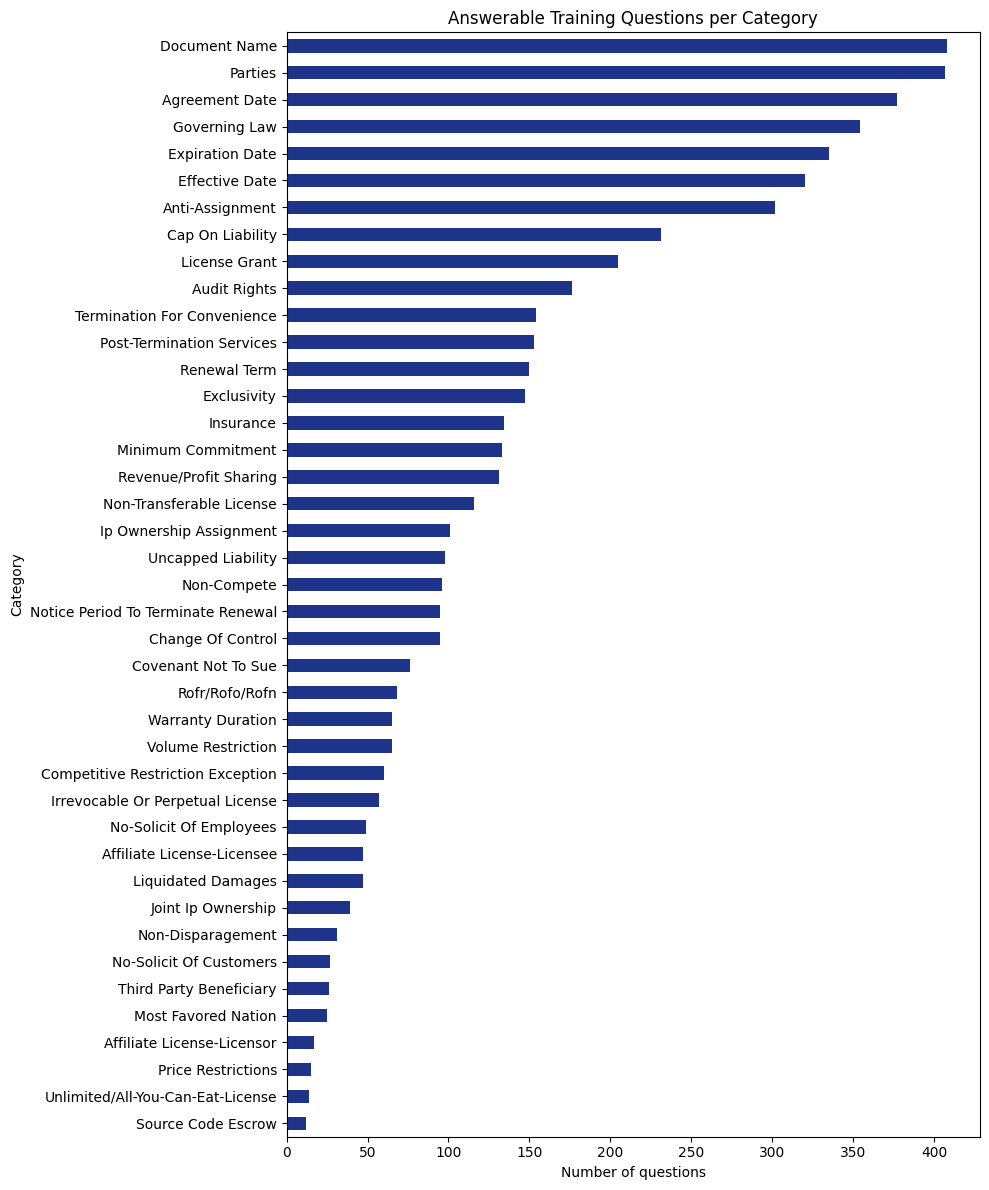

In [12]:
category_summary['answerable_questions'].sort_values().plot(
    kind='barh', figsize=(10, 12), color='#1d348a',
    title='Answerable Training Questions per Category'
)
plt.xlabel('Number of questions')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

f. checking answerability and multiple evidence spans

Keep unanswered questions for training the model to abstain. Preserve all annotated spans: multiple spans may refer to different relevant passages, rather than interchangeable wording for one answer.

In [13]:
answerability = df['is_impossible'].map({False: 'Answerable', True: 'Unanswerable'})
answerability_summary = answerability.value_counts().to_frame('questions')
answerability_summary['percentage'] = (
    answerability_summary['questions'] / len(df) * 100
).round(2)
answerability_summary

,questions,percentage
is_impossible,,
Unanswerable,11270,67.37
Answerable,5458,32.63


In [14]:
df['answer_count'].value_counts().sort_index().to_frame('questions')

,questions
answer_count,
0,11270
1,3335
2,877
3,387
4,383
5,205
6,73
7,74
8,32


g. checking evidence offsets

Each answer must match the exact context substring at `answer_start`. Do this before cleaning text: changing whitespace can invalidate the original offsets.

In [15]:
span_rows = []

for row in df.itertuples():
    for answer in row.answers:
        start = answer['answer_start']
        text = answer['text']
        end = start + len(text)

        span_rows.append({
            'id': row.id,
            'category': row.category,
            'answer_text': text,
            'answer_start': start,
            'answer_end': end,
            'offset_valid': 0 <= start < end <= len(row.context),
            'text_matches': row.context[start:end] == text,
            'answer_words': len(text.split())
        })

spans = pd.DataFrame(span_rows)
invalid_spans = spans.loc[~spans['offset_valid'] | ~spans['text_matches']]

pd.Series({
    'checked_spans': len(spans),
    'invalid_spans': len(invalid_spans)
}, name='count').to_frame()

,count
checked_spans,11180
invalid_spans,0


In [16]:
invalid_spans.head()

,id,category,answer_text,answer_start,answer_end,offset_valid,text_matches,answer_words


h. checking contract and evidence lengths

These are **word counts**, which give an initial overview. They are not model token counts. Before choosing a maximum sequence length or overlap, repeat this check with the exact DeBERTa tokenizer and account for question and special tokens.

In [17]:
train_contracts = contracts.loc[contracts['split'] == 'train'].copy()
train_contracts['contract_words'] = train_contracts['context'].str.split().str.len()

length_summary = pd.DataFrame({
    'contract_words': train_contracts['contract_words'].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ),
    'answer_words': spans['answer_words'].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
})
length_summary.round(1)

,contract_words,answer_words
count,408.0,11180.0
mean,8045.1,40.8
std,8300.2,43.5
min,170.0,1.0
50%,5357.5,31.0
90%,18679.3,91.0
95%,25224.1,117.0
99%,41890.2,208.0
max,45650.0,479.0


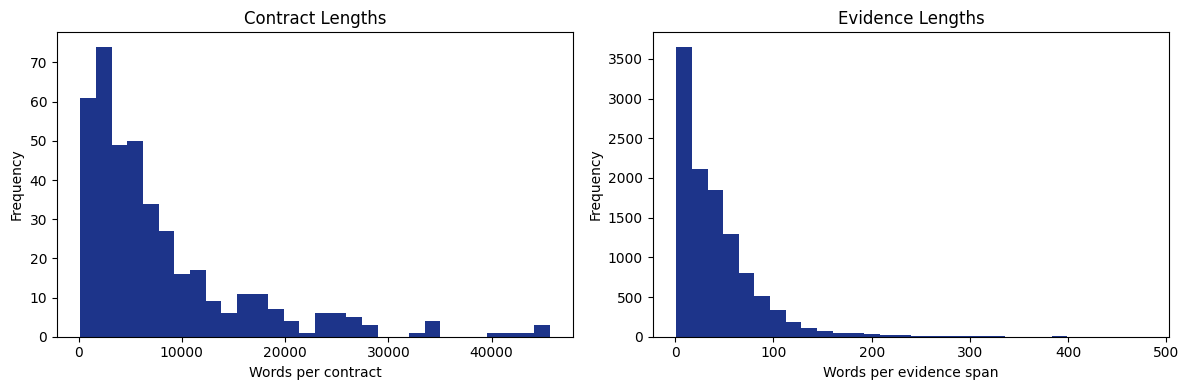

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_contracts['contract_words'].plot(
    kind='hist', bins=30, ax=axes[0], color='#1d348a', title='Contract Lengths'
)
axes[0].set_xlabel('Words per contract')

spans['answer_words'].plot(
    kind='hist', bins=30, ax=axes[1], color='#1d348a', title='Evidence Lengths'
)
axes[1].set_xlabel('Words per evidence span')

plt.tight_layout()
plt.show()

i. preparing a candidate training format

Keep one canonical record per original question, with every evidence span and its character offset. Empty answer lists represent unanswered questions. This previews the format without exporting or changing the source data.

After chunking, offsets must be relative to the chunk. Tokenisation then converts character offsets into start/end token labels. A standard single-span QA head needs an explicit strategy for questions with multiple spans; do not silently keep only the first answer.

In [19]:
training_df = df[
    ['id', 'contract_id', 'category', 'question', 'context', 'is_impossible']
].copy()
training_df['answers'] = df['answers'].apply(lambda answers: {
    'text': [answer['text'] for answer in answers],
    'answer_start': [answer['answer_start'] for answer in answers]
})
training_df['split'] = 'train'

training_df[['id', 'category', 'answers', 'split']].head()

,id,category,answers,split
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Document Name,"{'text': ['DISTRIBUTOR AGREEMENT'], 'answer_st...",train
1,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Parties,"{'text': ['Distributor', 'Electric City Corp.'...",train
2,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Agreement Date,"{'text': ['7th day of September, 1999.'], 'ans...",train
3,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Effective Date,{'text': ['The term of this Agreement shall ...,train
4,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Expiration Date,{'text': ['The term of this Agreement shall ...,train


j. decisions before training

Use the results above to record:

- **Categories:** which topics fit the project scope and have enough answerable contracts?
- **Validation split:** which training contracts are held out, using a fixed seed?
- **Chunking:** what token length and overlap preserve complete evidence spans? Measure gold-span coverage before choosing settings.
- **Multiple answers:** how will all valid spans contribute to training and evaluation?
- **Negative examples:** what balance of answerable and unanswerable chunks will be used? Check against every gold span before labelling a chunk negative.
- **Data quality:** do offset mismatches or duplicates require investigation? Exact-text checks above do not detect near-duplicate contracts.

Keep the original text and IDs for traceability. BM25 needs passages and gold-passage mappings; DeBERTa needs question-context-span examples. Gemma simplification targets come from the separate simplification data described in the proposal.

This initial notebook does not choose token window settings or export final training data. Those steps follow the tokenizer and chunk-coverage checks.